<a href="https://colab.research.google.com/github/lilyzhengliwang/Problem-Set-1/blob/main/Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

*The houshold of choice will be a mid-income household with two earners who drive to work every day and two college-aged dependents with no income. They would spend mostly on mortgage payments, tuition, car / transportation, groceries.*

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [2]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    # {"Item": ..., "Price_2019": ..., "Price_2024": ..., "weight": ...},
]

In [3]:
# making categories, prices, & weights
household_basket = [
    {'Item': 'homeownership', 'Price_2019':2100, 'Price_2024':2300, 'weight': 0.3},
    {'Item': 'transportation', 'Price_2019':1050, 'Price_2024':1350, 'weight': 0.15},
    {'Item': 'tuition', 'Price_2019':1400, 'Price_2024':1550, 'weight': 0.2},
    {'Item': 'groceries', 'Price_2019':700, 'Price_2024':875, 'weight': 0.1},
    {'Item': 'utilities', 'Price_2019':350, 'Price_2024':440, 'weight': 0.05},
    {'Item': 'healthcare', 'Price_2019':700, 'Price_2024':840, 'weight': 0.1},
    {'Item': 'recreation', 'Price_2019':350, 'Price_2024':390, 'weight': 0.05},
    {'Item': 'communications', 'Price_2019':350, 'Price_2024':365, 'weight': 0.05},
]

In [4]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

8 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [5]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""

    laspeyres_index = 0
    base_period = 100

    for i in basket:

      relative_price = i[current_key] / i[base_key]
      weight = i['weight']
      weighted_contribution = relative_price * weight

      laspeyres_index += weighted_contribution

    laspeyres_index = laspeyres_index * base_period

    return laspeyres_index

In [6]:
# 1. the unweighted average price change across categories

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")

# 3. the gap between them

In [7]:
# calculating unweighted average price changes
def unweighted_change(basket, base_key, current_key):
    """unweighted price index for `basket`, with the base period = 100."""

    unweighted_index = 0
    base_period = 100

    for i in basket:

      relative_price = i[current_key] / i[base_key]

      unweighted_index += relative_price

    unweighted_index = (unweighted_index * base_period) / len(basket)

    return unweighted_index

unweighted = unweighted_change(household_basket, 'Price_2019', 'Price_2024')

print(f'The unweighted average price change across categories is {unweighted / 100:.2f}% from 2019 to 2024, with an unweighted 2024 index of {unweighted:.2f}')


The unweighted average price change across categories is 1.17% from 2019 to 2024, with an unweighted 2024 index of 116.90


In [8]:
# weighted Laspeyres index

weighted_laspeyres = laspeyres(household_basket, 'Price_2019', 'Price_2024')
print(f'The weighted Laspeyres index shows a change of {weighted_laspeyres/100:.2f}% from 2019 to 2024, with a weighted 2024 index of {weighted_laspeyres:.2f}')

The weighted Laspeyres index shows a change of 1.16% from 2019 to 2024, with a weighted 2024 index of 115.86


In [9]:
# calculating gap between unweighted and weighted indexes

gap = unweighted - weighted_laspeyres
print(f'The unweighted index was about {gap:.2f} index points higher than the weighted Laspeyres index')

The unweighted index was about 1.05 index points higher than the weighted Laspeyres index


In [10]:
# calculating pct change in each category
def change(basket, base_key, current_key):
    """change for each category in `basket`."""

    for i in basket:

      i['change'] = round((i[current_key] - i[base_key]) / i[base_key], 2)

    return basket

basket_changes = change(household_basket, 'Price_2019', 'Price_2024')
print(basket_changes)


[{'Item': 'homeownership', 'Price_2019': 2100, 'Price_2024': 2300, 'weight': 0.3, 'change': 0.1}, {'Item': 'transportation', 'Price_2019': 1050, 'Price_2024': 1350, 'weight': 0.15, 'change': 0.29}, {'Item': 'tuition', 'Price_2019': 1400, 'Price_2024': 1550, 'weight': 0.2, 'change': 0.11}, {'Item': 'groceries', 'Price_2019': 700, 'Price_2024': 875, 'weight': 0.1, 'change': 0.25}, {'Item': 'utilities', 'Price_2019': 350, 'Price_2024': 440, 'weight': 0.05, 'change': 0.26}, {'Item': 'healthcare', 'Price_2019': 700, 'Price_2024': 840, 'weight': 0.1, 'change': 0.2}, {'Item': 'recreation', 'Price_2019': 350, 'Price_2024': 390, 'weight': 0.05, 'change': 0.11}, {'Item': 'communications', 'Price_2019': 350, 'Price_2024': 365, 'weight': 0.05, 'change': 0.04}]


**Why do the two differ, and which would you defend to the client?**

The two differ because the unweighted index treats every category equally, meaning that a category making up 30% of household spending would get the same weight as a category making up 5%. On the other hand, the Laspeyres index takes into account the different weights of the buckets, so it is more accurate, and I would defend that to the client. The unweighted index in this case is 116.90, while the weighted Laspeyres index is 115.86. Since smaller categories such as groceries and utilities rose more dramatically (e.g., +26%) than larger categories like homeownership and tuition (e.g., +11%), the unweighted index overstated the effect of the smaller categories' price changes, thus creating a 1.05 index point difference. The Laspeyres index is the better choice to use because it better reflects how the household actually spends their money. However, it does assume a fixed basket of goods and does not take into consideration switching to less expensive substitutes when prices rise.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [11]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02", 'CUSR0000SEEB', 'CUUR0000SAH2', 'CPIMEDNS', 'CUUR0000SAE2', 'CPIRECSL', 'CUUR0000SAT1']

| Series | Index | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|---|
| `CPIAUCSL` |All items |Reflects an avergae household; it the benchmark we are testing against|It is not exactly our two mid income earner with 2 college aged dependents household|
|`CUSR0000SEHA`|Rent|Similar to homeownership costs like monthly mortgage|Does not take into account downpayments, property taxes, fixed mortgage rates|
|`CUSR0000SAF11`|Food at Home |Representative of groceries|Does not include eating out|
|`CUSR0000SETA02`|Used Cars & Trucks |Represents purchase cost of vehicles|Does not include gas or maintenance|
|`CUSR0000SEEB`|Tuition|Representative of full tuition|Excludes financial aid, room & board; also may not be specific to college|
|`CUUR0000SAH2`|Fuel & Utilities|Includes most major utilities|Does not include local rates and varying usage rates|
|`CPIMEDNS`|Medical Care|Includes insurance & professional services|Does not track copay|
|`CUUR0000SAE2`|Communications|Includes phone, internet, TV servcies|Household may not have TV service|
|`CPIRECSL`|Recreation|Includes pets, sports, theaters, etc.|Very broad, not specific to the family|
|`CUUR0000SAT1`|Private Transportation|Includes overall cost of owning & operating private vehicles|Does not account for how many vehicles owned or higher insurance for young drivers|

In [12]:
# loading FRED series

def load_fred(series_id, start=None, end=None):

    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()

from pathlib import Path
Path("figures").mkdir(exist_ok=True)

series_ids = {
    "CPIAUCSL":       "All items (headline CPI)",
    "CUSR0000SEHA":   "Rent",
    "CUSR0000SAF11":  "Food at home",
    "CUSR0000SETA02": "Used cars & trucks",
    "CUSR0000SEEB":   "Tuition",
    "CUUR0000SAH2":   "Fuel & utilities",
    "CPIMEDNS":       "Medical care",
    "CUUR0000SAE2":   "Communications",
    "CPIRECSL":       "Recreation",
    "CUUR0000SAT1":   "Private transportation",
}

raw = {}
for sid in series_ids:
    try:
        raw[sid] = load_fred(sid, start="1947-01-01")
    except Exception as e:
        print(f"FAILED: {sid} -> {e}")

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [13]:
# Rebase to 2019 = 100

rebased = {sid: s / s.loc["2019"].mean() * 100 for sid, s in raw.items()}

hh_2024 = laspeyres(household_basket, "Price_2019", "Price_2024")
hh = pd.Series({pd.Timestamp("2019-07-01"): 100.0,
                pd.Timestamp("2024-07-01"): hh_2024})



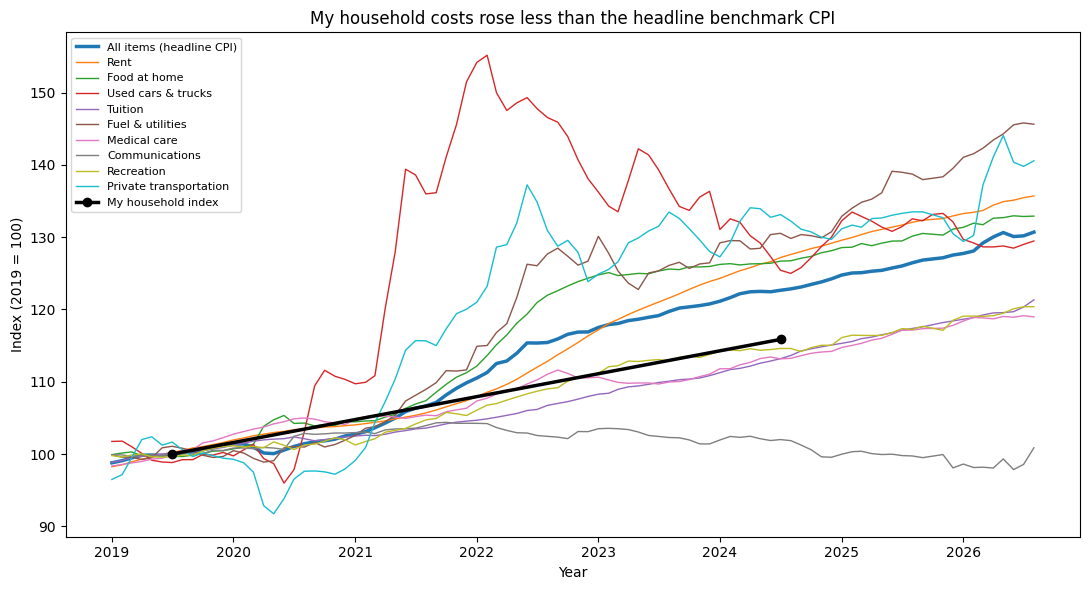

In [14]:
# One chart: every rebased series, plus your household index

fig, ax = plt.subplots(figsize=(11, 6))
for sid, s in rebased.items():
    s_plot = s.loc["2019":]
    ax.plot(s_plot.index, s_plot, label=series_ids[sid],
            linewidth=2.5 if sid == "CPIAUCSL" else 1.0)
ax.plot(hh.index, hh, "ko-", linewidth=2.5, label="My household index")
ax.set_xlabel("Year")
ax.set_ylabel("Index (2019 = 100)")
ax.set_title("My household costs rose less than the headline benchmark CPI")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("figures/phase2_rebased.png", dpi=150)
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [15]:
# First observation, last observation, frequency and missing months, for every series

audit_rows = []
missing_by_series = {}

for sid, s in raw.items():
    grid = s.asfreq("MS")
    missing = grid[grid.isna()].index
    missing_by_series[sid] = list(missing.strftime("%Y-%m"))
    audit_rows.append({
        "Series": sid,
        "Name": series_ids[sid],
        "First": s.index.min().strftime("%Y-%m"),
        "Last": s.index.max().strftime("%Y-%m"),
        "Frequency": "Monthly",
        "Number of Observations": len(s),
        "Missing number of months": int(grid.isna().sum()),
    })

audit = pd.DataFrame(audit_rows).set_index("Series")
display(audit)

audit = pd.DataFrame(audit_rows).set_index("Series")
display(audit)

for sid, months in missing_by_series.items():
    if months:
        print(f"{sid}: {len(months)} missing -> {months}")
    else:
        print(f"{sid}: zero missing months")

,Name,First,Last,Frequency,Number of Observations,Missing number of months
Series,,,,,,
CPIAUCSL,All items (headline CPI),1947-01,2026-08,Monthly,955,1
CUSR0000SEHA,Rent,1981-01,2026-08,Monthly,547,1
CUSR0000SAF11,Food at home,1952-01,2026-08,Monthly,895,1
CUSR0000SETA02,Used cars & trucks,1953-01,2026-08,Monthly,884,0
CUSR0000SEEB,Tuition,1978-01,2026-08,Monthly,583,1
CUUR0000SAH2,Fuel & utilities,1952-12,2026-08,Monthly,884,1
CPIMEDNS,Medical care,1947-01,2026-08,Monthly,955,1
CUUR0000SAE2,Communications,1993-01,2026-08,Monthly,403,1
CPIRECSL,Recreation,1993-01,2026-08,Monthly,403,1


,Name,First,Last,Frequency,Number of Observations,Missing number of months
Series,,,,,,
CPIAUCSL,All items (headline CPI),1947-01,2026-08,Monthly,955,1
CUSR0000SEHA,Rent,1981-01,2026-08,Monthly,547,1
CUSR0000SAF11,Food at home,1952-01,2026-08,Monthly,895,1
CUSR0000SETA02,Used cars & trucks,1953-01,2026-08,Monthly,884,0
CUSR0000SEEB,Tuition,1978-01,2026-08,Monthly,583,1
CUUR0000SAH2,Fuel & utilities,1952-12,2026-08,Monthly,884,1
CPIMEDNS,Medical care,1947-01,2026-08,Monthly,955,1
CUUR0000SAE2,Communications,1993-01,2026-08,Monthly,403,1
CPIRECSL,Recreation,1993-01,2026-08,Monthly,403,1


CPIAUCSL: 1 missing -> ['2025-10']
CUSR0000SEHA: 1 missing -> ['2025-10']
CUSR0000SAF11: 1 missing -> ['2025-10']
CUSR0000SETA02: zero missing months
CUSR0000SEEB: 1 missing -> ['2025-10']
CUUR0000SAH2: 1 missing -> ['2025-10']
CPIMEDNS: 1 missing -> ['2025-10']
CUUR0000SAE2: 1 missing -> ['2025-10']
CPIRECSL: 1 missing -> ['2025-10']
CUUR0000SAT1: 1 missing -> ['2025-10']


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| | | | | |

All the missing months are October 2025, and this is due to the government shutdown, and the Bureau of Labor Statistics states that. We will leave it as NaN and exclude from calculations.

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [16]:
# Start dates side by side, and the common sample

# use raw grid from earlier, Oct 2025 shows as NaN
raw_grid = {sid: s.asfreq("MS") for sid, s in raw.items()}

dates = pd.DataFrame({
    "name":  pd.Series(series_ids),
    "start": pd.Series({sid: s.dropna().index.min() for sid, s in raw_grid.items()}),
    "end":   pd.Series({sid: s.dropna().index.max() for sid, s in raw_grid.items()}),
}).sort_values("start")
display(dates)


,name,start,end
CPIAUCSL,All items (headline CPI),1947-01-01,2026-08-01
CPIMEDNS,Medical care,1947-01-01,2026-08-01
CUUR0000SAT1,Private transportation,1947-01-01,2026-08-01
CUSR0000SAF11,Food at home,1952-01-01,2026-08-01
CUUR0000SAH2,Fuel & utilities,1952-12-01,2026-08-01
CUSR0000SETA02,Used cars & trucks,1953-01-01,2026-08-01
CUSR0000SEEB,Tuition,1978-01-01,2026-08-01
CUSR0000SEHA,Rent,1981-01-01,2026-08-01
CUUR0000SAE2,Communications,1993-01-01,2026-08-01
CPIRECSL,Recreation,1993-01-01,2026-08-01


In [17]:
# three numbers for common sample

common_start = dates["start"].max()
common_end   = dates["end"].min()
n_common     = len(pd.date_range(common_start, common_end, freq="MS"))

longest_sid  = dates["start"].idxmin()
n_longest    = len(raw_grid[longest_sid])
n_discarded  = n_longest - n_common

print(f"Common sample start:  {common_start:%Y-%m} (set by {dates['start'].idxmax()})")
print(f"Common sample end:    {common_end:%Y-%m}")
print(f"Common sample length:  {n_common} months")
print(f"Longest series:        {longest_sid} ({n_longest} months)")
print(f"Months discarded from longest series:      {n_discarded}")

Common sample start:  1993-01 (set by CUUR0000SAE2)
Common sample end:    2026-08
Common sample length:  404 months
Longest series:        CPIAUCSL (956 months)
Months discarded from longest series:      552


In [18]:
# Headline comparison: full history vs common sample

def annual_growth(s):
    s = s.dropna()
    years = (s.index[-1] - s.index[0]).days / 365.25
    return ((s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1) * 100

full   = pd.Series({sid: annual_growth(s) for sid, s in raw_grid.items()})
common = pd.Series({sid: annual_growth(s.loc[common_start:common_end])
                    for sid, s in raw_grid.items()})

compare = pd.DataFrame({
    "name": pd.Series(series_ids),
    "full_history_yearly_%": full,
    "common_sample_yearly_%": common,
})
compare["change (pct pt)"] = compare["common_sample_yearly_%"] - compare["full_history_yearly_%"]
compare["gap_vs_CPI_full (pct pt)"]   = compare["full_history_yearly_%"]   - full["CPIAUCSL"]
compare["gap_vs_CPI_common (pct pt)"] = compare["common_sample_yearly_%"] - common["CPIAUCSL"]
display(compare.round(2))

,name,full_history_yearly_%,common_sample_yearly_%,change (pct pt),gap_vs_CPI_full (pct pt),gap_vs_CPI_common (pct pt)
CPIAUCSL,All items (headline CPI),3.51,2.56,-0.94,0.00,0.00
CUSR0000SEHA,Rent,3.73,3.34,-0.38,0.22,0.78
CUSR0000SAF11,Food at home,3.18,2.55,-0.63,-0.33,-0.02
CUSR0000SETA02,Used cars & trucks,2.53,1.05,-1.48,-0.97,-1.51
CUSR0000SEEB,Tuition,5.89,4.40,-1.49,2.38,1.83
CUUR0000SAH2,Fuel & utilities,3.83,3.29,-0.54,0.32,0.72
CPIMEDNS,Medical care,4.90,3.35,-1.55,1.39,0.78
CUUR0000SAE2,Communications,-0.80,-0.80,0.00,-4.31,-3.36
CPIRECSL,Recreation,1.44,1.44,0.00,-2.06,-1.12
CUUR0000SAT1,Private transportation,3.41,2.49,-0.92,-0.10,-0.07


Directionally, both are the same, as all the categories of proxies have the same signs. However, the magnitude is different for some; for example, the headline CPI drops by 0.94 pct pts when we restrict to common sample, because it cuts out inflation from the 1970s. Since the client is asking whether to raise wages now, the 1970s may not be as relevant, so I would show them the common sample, since it is a cleaner comparison over the same period of time.

**What restricting to the common sample assumes, and what not restricting assumes:**

Restricting to the common sample assumes that the period is representative of growth rates and trends, whereas not restricting assumes that the growth rates measured over different time periods are comparable and that the information is valuable, such as an earlier period of stagflation in the 1970s that affected indexes later on.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

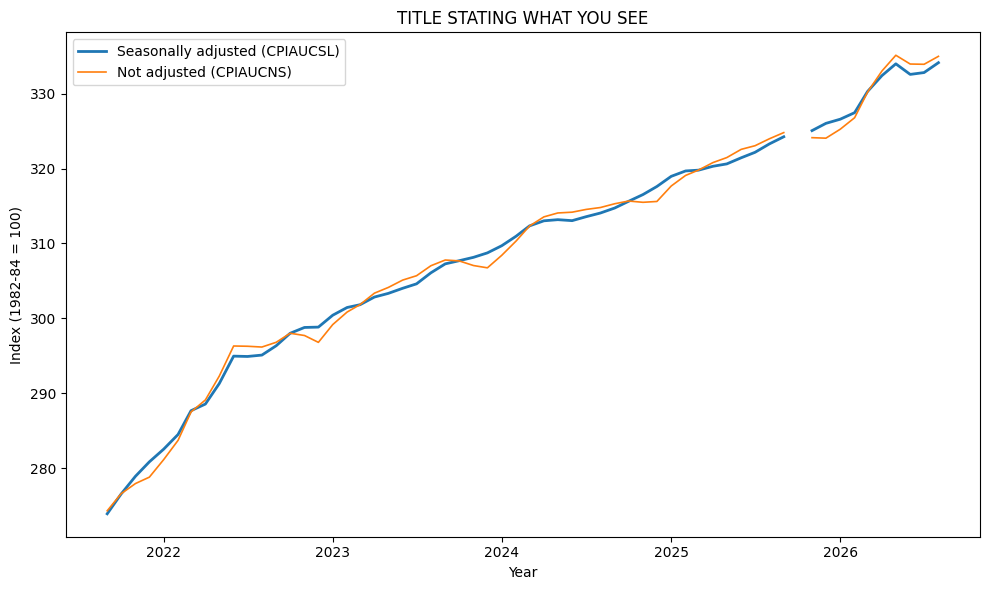

count    59.00
mean      0.01
std       1.02
min      -2.04
25%      -0.86
50%       0.40
75%       0.86
max       1.38
dtype: float64
Largest positive gap: 2026-06 1.38
Largest negative gap: 2021-12 -2.04


In [19]:
# Seasonally adjusted vs unadjusted, last five years
# choosing the headline CPI

sa_id, nsa_id = "CPIAUCSL", "CPIAUCNS"
sa  = load_fred(sa_id,  start="2019-01-01").asfreq("MS")
nsa = load_fred(nsa_id, start="2019-01-01").asfreq("MS")

# last five years
end = min(sa.dropna().index.max(), nsa.dropna().index.max())
window = pd.date_range(end=end, periods=60, freq="MS")
sa, nsa = sa.loc[window], nsa.loc[window]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(sa.index,  sa,  label="Seasonally adjusted (CPIAUCSL)", linewidth=2)
ax.plot(nsa.index, nsa, label="Not adjusted (CPIAUCNS)", linewidth=1.2)
ax.set_xlabel("Year")
ax.set_ylabel("Index (1982-84 = 100)")
ax.set_title("TITLE STATING WHAT YOU SEE")
ax.legend()
plt.tight_layout()
plt.savefig("figures/phase3_sa_vs_nsa.png", dpi=150)
plt.show()


gap = nsa - sa
#summary statistics for the gap
print(gap.describe().round(2))
print("Largest positive gap:", gap.idxmax().strftime("%Y-%m"), round(gap.max(), 2))
print("Largest negative gap:", gap.idxmin().strftime("%Y-%m"), round(gap.min(), 2))

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap between the two lines reflect seasonal factors that affect the data. For example, things such as spikes in spending around holidays or other predictable trends related to seasonality are taken into account and adjusted for. Since the client pays unadjusted prices, the unadjusted series is the appropriate one to include in this brief. Also, unadjusted data does not change while seasonally adjusted data is usually updated monthly, so it could change between our recommendation and the actual implementation.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

##AI Transcript

### AI Transcript

**Model:** Claude Sonnet 5.5 &nbsp; **Date:** October 9, 2026

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

Prompt:
[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.

I ran this against your household_basket. Your basket has eight categories, not the six the prompt says, so the code loops over whatever is in the list rather than assuming six. If the six in the prompt is a typo, you may want to fix it in the transcript.

python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

basket_df = pd.DataFrame(household_basket)
basket_df["relative"] = basket_df["Price_2024"] / basket_df["Price_2019"]   # price relative per category

base_weights = basket_df["weight"].to_numpy()
relatives = basket_df["relative"].to_numpy()
items = basket_df["Item"].tolist()

def index_from_weights(w):
    # Base-weighted Laspeyres: sum of weight x price relative, scaled so 2019 = 100
    return 100 * np.sum(w * relatives)

base_index = index_from_weights(base_weights)
grid = np.linspace(0, 0.5, 51)

def reweight(base_w, k, new_wk):
    # Why renormalise: weights are shares of one budget, so they must sum to 1.0.
    # If we raised one weight and left the rest alone, the total would exceed 1.0
    # and the "index" would no longer describe a household spending 100% of its budget.
    # Scaling the others by the same factor keeps their relative mix unchanged,
    # so any movement in the index is caused only by the category being swept.
    w = base_w.copy()
    others = np.arange(len(w)) != k
    w[others] = base_w[others] * (1 - new_wk) / base_w[others].sum()
    w[k] = new_wk
    return w

sweep = {}
for k, item in enumerate(items):
    sweep[item] = np.array([index_from_weights(reweight(base_weights, k, g)) for g in grid])
sweep_df = pd.DataFrame(sweep, index=grid)
sweep_df.index.name = "weight"

# Sanity checks: weights always sum to 1, and the baseline weight reproduces the baseline index
for k in range(len(items)):
    assert np.isclose(reweight(base_weights, k, 0.37).sum(), 1.0)
    assert np.isclose(index_from_weights(reweight(base_weights, k, base_weights[k])), base_index)

# Sensitivity = how far the index swings across the 0 to 0.5 sweep
swing = sweep_df.max() - sweep_df.min()
order = swing.sort_values(ascending=False).index

# If the index were highly sensitive to one category, the headline number would
# depend mainly on a single weight, which is a judgement call and not data.
# A client could then get a very different answer by disagreeing about that one
# weight, so the result should be presented as a range, not a point.
fig, ax = plt.subplots(figsize=(10, 6))
for item in order:
    ax.plot(sweep_df.index, sweep_df[item], label=f"{item} (swing {swing[item]:.1f} pts)")
ax.axhline(base_index, color="black", linestyle=":", linewidth=1, label=f"baseline {base_index:.1f}")
ax.set_xlabel("Weight on category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title("Index sensitivity to each category's weight")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(swing.sort_values(ascending=False).round(2))

Which category dominates. Transportation, and by a clear margin. Sweeping its weight from 0 to 0.5 moves the index by about 7.5 points (113.6 to 121.1), followed by communications at about 6.1 points, utilities at 5.2, groceries at 5.1, homeownership at 4.5, tuition at 3.2, recreation at 2.3 and healthcare at 2.3. Your baseline is 115.86.

The reason is how far a category’s price change sits from the rest of the basket. Transportation rose 29% (1,050 to 1,350), the largest in your basket, so shifting weight toward it pulls the index up. Communications rose only 4%, so shifting weight toward it pulls the index down. Categories whose price rise is close to the basket average barely matter, whatever their weight.

What to say to a client. The index is robust but not fully insensitive. Across every reweighting tested, it stays between about 110 and 121, so the headline that this household’s costs rose roughly 16% since 2019 holds up, and no single weight assumption can overturn it. The weight that matters most is the share spent on transportation. If the client’s workers spend more of their budget on commuting than the 15% assumed, the household’s cost increase would look larger, and if less, smaller. I would present the result as “about 16%, plausibly 14 to 21% depending on transport share,” and say that the transport weight is the assumption most worth checking against real worker data.

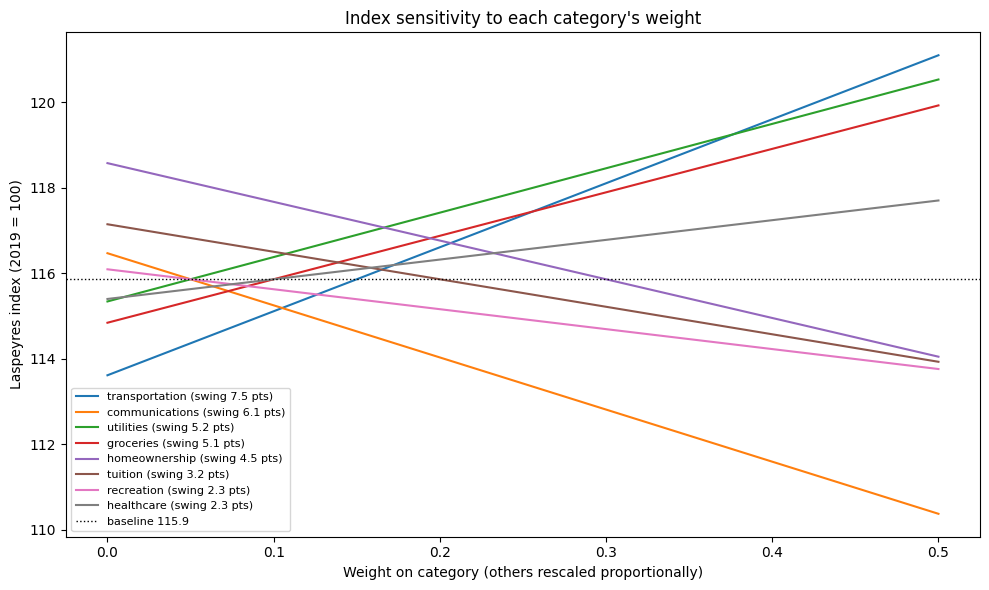

transportation    7.48
communications    6.09
utilities         5.19
groceries         5.08
homeownership     4.52
tuition           3.21
recreation        2.33
healthcare        2.30
dtype: float64


In [20]:
# Paste the AI's code here, run it, and correct it where it is wrong

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

basket_df = pd.DataFrame(household_basket)
basket_df["relative"] = basket_df["Price_2024"] / basket_df["Price_2019"]   # price relative per category

base_weights = basket_df["weight"].to_numpy()
relatives = basket_df["relative"].to_numpy()
items = basket_df["Item"].tolist()

def index_from_weights(w):
    # Base-weighted Laspeyres: sum of weight x price relative, scaled so 2019 = 100
    return 100 * np.sum(w * relatives)

base_index = index_from_weights(base_weights)
grid = np.linspace(0, 0.5, 51)

def reweight(base_w, k, new_wk):
    # Why renormalise: weights are shares of one budget, so they must sum to 1.0.
    # If we raised one weight and left the rest alone, the total would exceed 1.0
    # and the "index" would no longer describe a household spending 100% of its budget.
    # Scaling the others by the same factor keeps their relative mix unchanged,
    # so any movement in the index is caused only by the category being swept.
    w = base_w.copy()
    others = np.arange(len(w)) != k
    w[others] = base_w[others] * (1 - new_wk) / base_w[others].sum()
    w[k] = new_wk
    return w

sweep = {}
for k, item in enumerate(items):
    sweep[item] = np.array([index_from_weights(reweight(base_weights, k, g)) for g in grid])
sweep_df = pd.DataFrame(sweep, index=grid)
sweep_df.index.name = "weight"

# Sanity checks: weights always sum to 1, and the baseline weight reproduces the baseline index
for k in range(len(items)):
    assert np.isclose(reweight(base_weights, k, 0.37).sum(), 1.0)
    assert np.isclose(index_from_weights(reweight(base_weights, k, base_weights[k])), base_index)

# Sensitivity = how far the index swings across the 0 to 0.5 sweep
swing = sweep_df.max() - sweep_df.min()
order = swing.sort_values(ascending=False).index

# If the index were highly sensitive to one category, the headline number would
# depend mainly on a single weight, which is a judgement call and not data.
# A client could then get a very different answer by disagreeing about that one
# weight, so the result should be presented as a range, not a point.
fig, ax = plt.subplots(figsize=(10, 6))
for item in order:
    ax.plot(sweep_df.index, sweep_df[item], label=f"{item} (swing {swing[item]:.1f} pts)")
ax.axhline(base_index, color="black", linestyle=":", linewidth=1, label=f"baseline {base_index:.1f}")
ax.set_xlabel("Weight on category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title("Index sensitivity to each category's weight")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(swing.sort_values(ascending=False).round(2))

**What did the model get wrong, or get right in a way you had to check? Show the check.**

The model said that the index stays in between about 110 and 121 and said plausibly 14% to 21%, but an index of 110 means 10%. Checked the lower and highest indexes, and the range will be ~10% to 21%. However, there is nothing wrong I found in the actual visualization or code, just the interpretation portion.

In [21]:
# checking index
lo_item = sweep_df.min().idxmin()
hi_item = sweep_df.max().idxmax()
print("Lowest index across all sweeps :", round(sweep_df.min().min(), 2), "->", lo_item)
print("Highest index across all sweeps:", round(sweep_df.max().max(), 2), "->", hi_item)


Lowest index across all sweeps : 110.38 -> communications
Highest index across all sweeps: 121.09 -> transportation


### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

In our hypothetical two-earner household with two college-age children, a mortgage and a daily commute saw its costs rise about 16% from 2019 to 2024, while the official consumer price index rose roughly 23%. For this household, the client’s suspicion that the index overstates their workers’ costs is supported.

The gap comes from what the household buys. The official index averages every American’s spending, including categories that rose sharply in the period. Our household spends little on those and a lot on housing and tuition, which rose more slowly.

We should be only modestly confident, not highly. Our spending figures are estimates, not survey data, and also spending categories and proportions of our hypothetical household could vary drastically from the workers' demographic. However, we tested how much the answer fluctuates; when we shifted the household’s budget toward the fastest-rising categories, the result stayed between roughly 10% and 21%, which is still below the official figure. The category that matters most is transportation: if workers spend more of their budget on commuting than we assumed, their costs would look higher.
Also, the official series for tuition, medical care, and rent have grown faster than the overall index, so these categories could push household's costs up if we checked them with real prices.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub